In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [7]:
from google.colab import files
import io

uploaded = files.upload()
# Dynamically get the uploaded file name to avoid KeyError from name increments
file_name = list(uploaded.keys())[0]
Df = pd.read_csv(io.BytesIO(uploaded[file_name]), encoding='ISO-8859-1')

Saving OnlineRetail.csv to OnlineRetail (2).csv


In [8]:
Df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [10]:
print("Shape of Dataset:", Df.shape)

print("\nColumns:")
print(Df.columns.tolist())

print("\nData Types:")
print(Df.dtypes)

Shape of Dataset: (541909, 8)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


In [12]:
Df.info()
Df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [14]:
print("Number of duplicate rows:", Df.duplicated().sum())

Number of duplicate rows: 5268


In [15]:
Df["InvoiceDate"] = pd.to_datetime(
    Df["InvoiceDate"],
    errors="coerce"
)

Df["InvoiceDate"].head()

,InvoiceDate
0,2010-12-01 08:26:00
1,2010-12-01 08:26:00
2,2010-12-01 08:26:00
3,2010-12-01 08:26:00
4,2010-12-01 08:26:00


In [16]:
Df = Df[~Df["InvoiceNo"].astype(str).str.startswith("C")]

print("Shape after removing cancelled orders:", Df.shape)

Shape after removing cancelled orders: (532621, 8)


In [17]:
Df = Df[Df["Quantity"] > 0]

Df = Df[Df["UnitPrice"] > 0]

Df = Df.dropna(subset=["Description"])

print("Shape after cleaning:", Df.shape)

Shape after cleaning: (530104, 8)


In [18]:
Df["Revenue"] = Df["Quantity"] * Df["UnitPrice"]

Df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [19]:
total_orders = Df["InvoiceNo"].nunique()

print("Total Orders:", total_orders)

Total Orders: 19960


In [20]:
orders_by_country = (
    Df.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

orders_by_country.head(10)

,InvoiceNo
Country,
United Kingdom,18019
Germany,457
France,392
EIRE,288
Belgium,98
Netherlands,94
Spain,90
Portugal,58
Australia,57


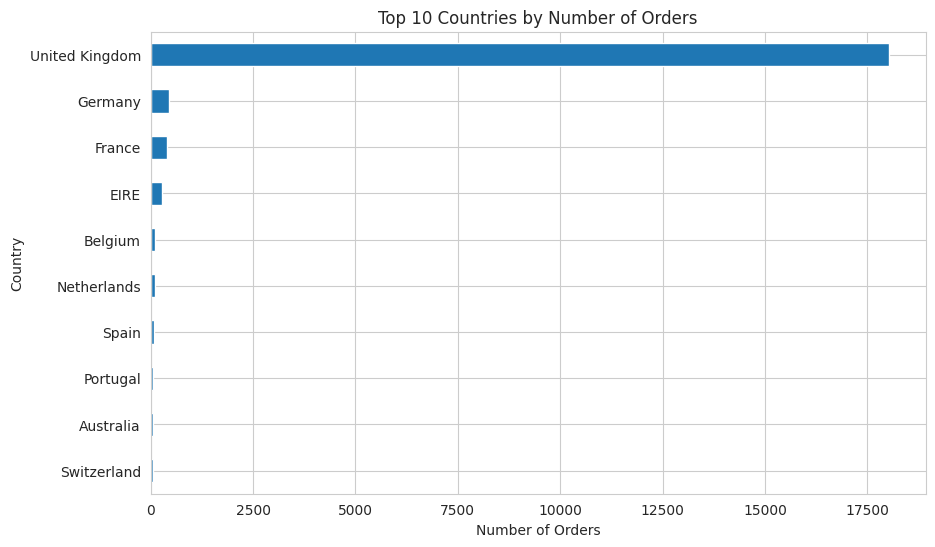

In [21]:
top_countries = orders_by_country.head(10)

plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Country")

plt.show()

In [22]:
total_revenue = Df["Revenue"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 10666684.54


In [23]:
average_order_value = total_revenue / total_orders

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 534.4


In [24]:
revenue_by_country = (
    Df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_country.head(10)

,Revenue
Country,
United Kingdom,9025222.084
Netherlands,285446.340
EIRE,283453.960
Germany,228867.140
France,209715.110
Australia,138521.310
Spain,61577.110
Switzerland,57089.900
Belgium,41196.340


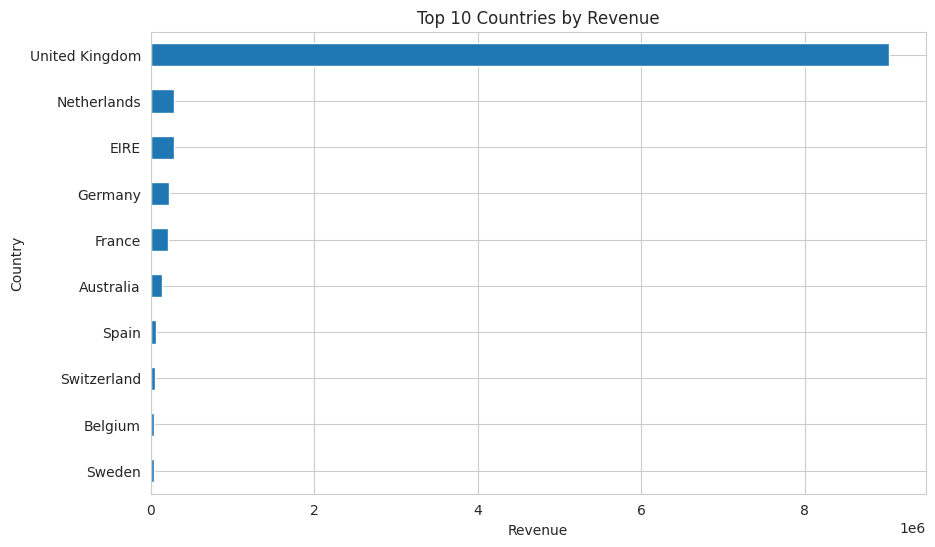

In [25]:
plt.figure(figsize=(10, 6))

revenue_by_country.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.show()

In [26]:
best_selling_products = (
    Df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

best_selling_products

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
JUMBO BAG RED RETROSPOT,48474
WHITE HANGING HEART T-LIGHT HOLDER,37891
POPCORN HOLDER,36761
ASSORTED COLOUR BIRD ORNAMENT,36461
PACK OF 72 RETROSPOT CAKE CASES,36419
RABBIT NIGHT LIGHT,30788


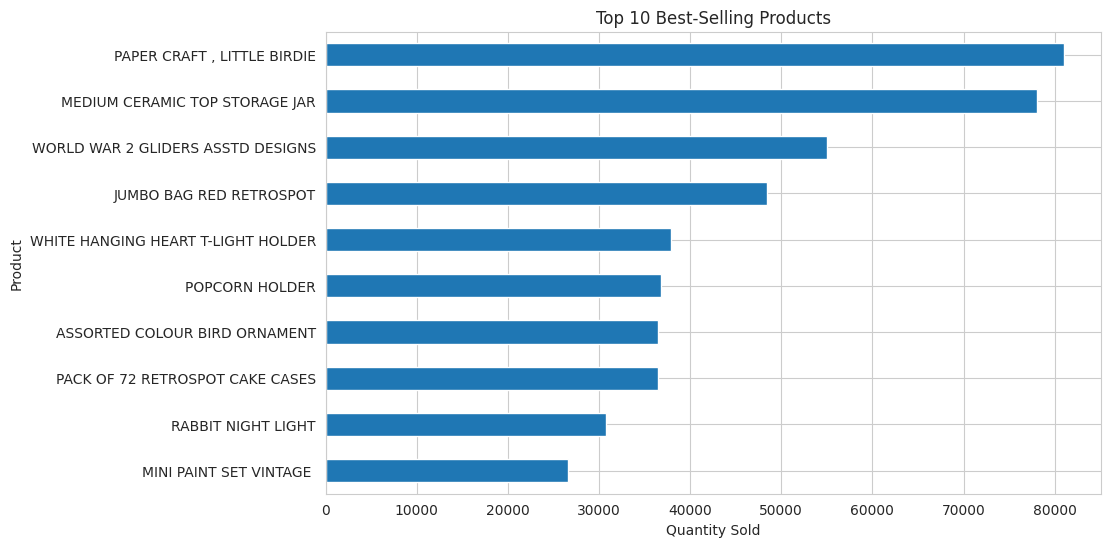

In [27]:
plt.figure(figsize=(10, 6))

best_selling_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.show()

In [29]:
top_products_revenue = (
    Df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_revenue

,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174484.74
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106292.77
PARTY BUNTING,99504.33
JUMBO BAG RED RETROSPOT,94340.05
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
Manual,78112.82
POSTAGE,78101.88


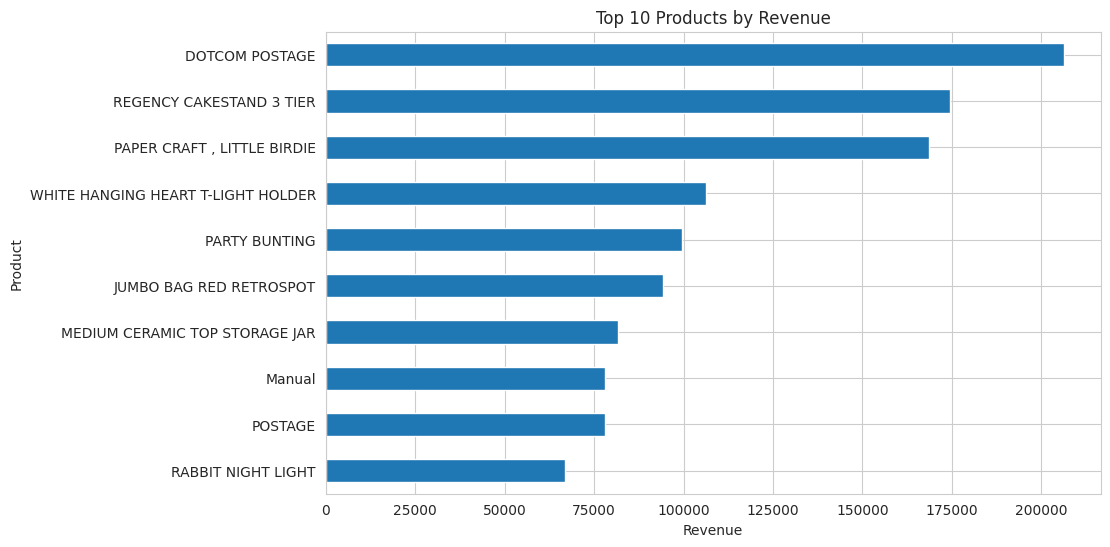

In [30]:
plt.figure(figsize=(10, 6))

top_products_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

In [31]:
def assign_category(description):
    text = str(description).upper()

    if any(word in text for word in ["MUG", "CUP", "PLATE", "BOWL", "KITCHEN"]):
        return "Home & Kitchen"

    elif any(word in text for word in ["TOY", "DOLL", "GAME", "PUZZLE"]):
        return "Toys & Games"

    elif any(word in text for word in ["BAG", "PURSE", "WALLET"]):
        return "Bags & Accessories"

    elif any(word in text for word in ["PEN", "PAPER", "NOTEBOOK", "DIARY"]):
        return "Stationery"

    elif any(word in text for word in ["GIFT", "CARD", "CHRISTMAS", "DECORATION"]):
        return "Gifts & Decorations"

    elif any(word in text for word in ["DRESS", "SHIRT", "SCARF", "COTTON"]):
        return "Clothing & Textiles"

    elif any(word in text for word in ["GARDEN", "PLANT", "FLOWER"]):
        return "Garden & Outdoor"

    else:
        return "Other"


Df["ProductCategory"] = Df["Description"].apply(assign_category)

Df[["Description", "ProductCategory"]].head(10)

,Description,ProductCategory
0,WHITE HANGING HEART T-LIGHT HOLDER,Other
1,WHITE METAL LANTERN,Other
2,CREAM CUPID HEARTS COAT HANGER,Home & Kitchen
3,KNITTED UNION FLAG HOT WATER BOTTLE,Other
4,RED WOOLLY HOTTIE WHITE HEART.,Other
5,SET 7 BABUSHKA NESTING BOXES,Other
6,GLASS STAR FROSTED T-LIGHT HOLDER,Other
7,HAND WARMER UNION JACK,Other
8,HAND WARMER RED POLKA DOT,Other
9,ASSORTED COLOUR BIRD ORNAMENT,Other


In [32]:
category_revenue = (
    Df.groupby("ProductCategory")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue

,Revenue
ProductCategory,
Other,7303654.824
Bags & Accessories,1106471.520
Gifts & Decorations,618306.000
Stationery,596322.400
Home & Kitchen,554393.550
Garden & Outdoor,242322.130
Toys & Games,226969.870
Clothing & Textiles,18244.250


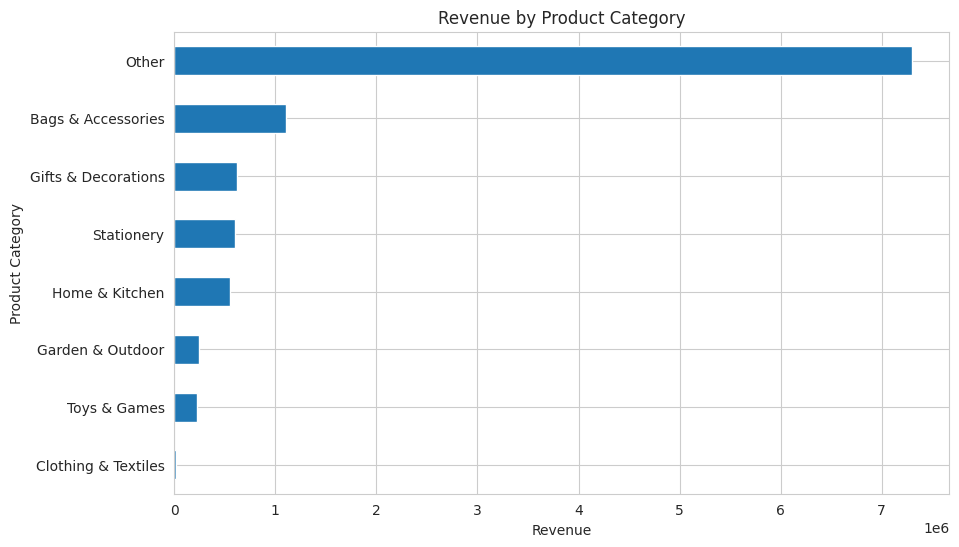

In [33]:
plt.figure(figsize=(10, 6))

category_revenue.sort_values().plot(kind="barh")

plt.title("Revenue by Product Category")
plt.xlabel("Revenue")
plt.ylabel("Product Category")

plt.show()

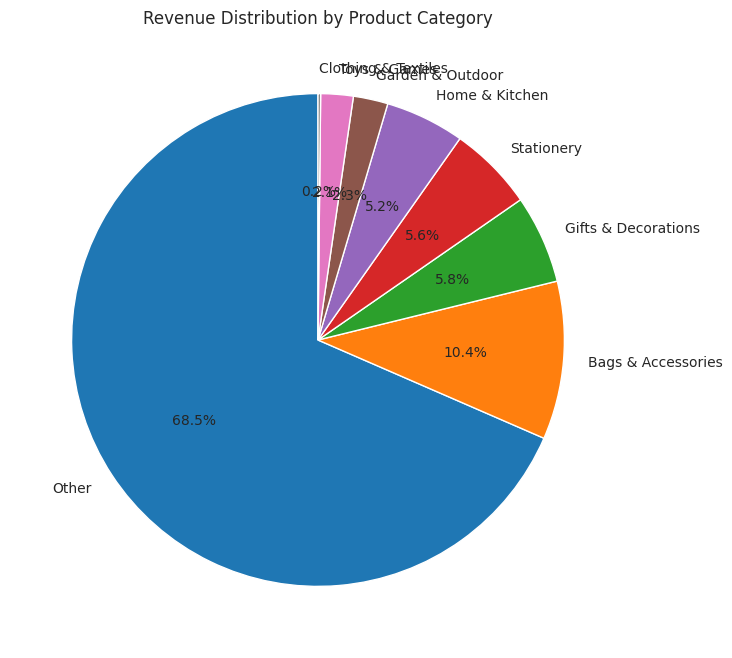

In [34]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Product Category")

plt.show()

In [35]:
monthly_revenue = (
    Df.set_index("InvoiceDate")
    .resample("ME")["Revenue"]
    .sum()
)

monthly_revenue

,Revenue
InvoiceDate,
2010-12-31,823746.140
2011-01-31,691364.560
2011-02-28,523631.890
2011-03-31,717639.360
2011-04-30,537808.621
2011-05-31,770536.020
2011-06-30,761739.900
2011-07-31,719221.191
2011-08-31,759138.380


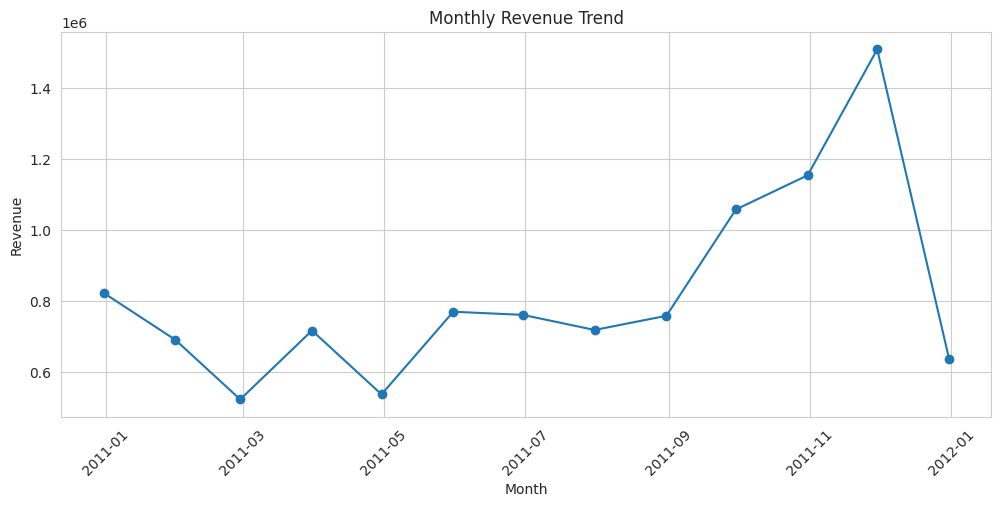

In [36]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

In [38]:
print("========== E-COMMERCE ANALYSIS SUMMARY ==========")

print(f"Total Orders: {total_orders:,}")
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Average Order Value: {average_order_value:,.2f}")
print(f"Total Customers: {Df['CustomerID'].nunique():,}")
print(f"Unique Products: {Df['StockCode'].nunique():,}")

print("\nTop Country by Orders:")
print(orders_by_country.index[0])

print("\nTop Product by Quantity Sold:")
print(best_selling_products.index[0])

print("\nTop Product by Revenue:")
print(top_products_revenue.index[0])

print("\nHighest Revenue Category:")
print(category_revenue.index[0])

========== E-COMMERCE ANALYSIS SUMMARY ==========
Total Orders: 19,960
Total Revenue: 10,666,684.54
Average Order Value: 534.40
Total Customers: 4,338
Unique Products: 3,922

Top Country by Orders:
United Kingdom

Top Product by Quantity Sold:
PAPER CRAFT , LITTLE BIRDIE

Top Product by Revenue:
DOTCOM POSTAGE

Highest Revenue Category:
Other
